In [2]:
import pandas as pd
from io import StringIO

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
path = "../data/Scenario A1-ARFF/TimeBasedFeatures-Dataset-15s-VPN.arff"

lines = open(path, encoding="utf-8", errors="replace").read().splitlines()

columns = []
data_start = None
for i, line in enumerate(lines):
    s = line.strip()
    if s.upper().startswith("@ATTRIBUTE"):
        columns.append(s.split()[1])   # the 2nd word on the line is the column name
    elif s.upper().startswith("@DATA"):
        data_start = i + 1             # data rows begin on the next line
        break

df = pd.read_csv(StringIO("\n".join(lines[data_start:])), header=None)
df = df.iloc[:, :len(columns)]         # drop any stray empty trailing columns
df.columns = columns

In [4]:
print("shape:", df.shape)
print(df["class1"].value_counts())
df.head(10)

shape: (18758, 24)
class1
VPN        9793
Non-VPN    8965
Name: count, dtype: int64


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,...,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,1.610965e+05,Non-VPN
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,...,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,2.731384e+05,Non-VPN
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,...,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000e+00,Non-VPN
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,...,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,7.749303e+05,Non-VPN
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,...,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,7.259878e+05,Non-VPN
5,11771793,30,6,3149632,2964504,244008.020833,255167.347826,632857.385277,607541.355370,8.155087,...,435676.952940,1443143,2.872733e+06,3563174,9.651035e+05,1065834,1933295.0,2964504,1.008645e+06,Non-VPN
6,13978645,17,7,2249885,2064514,215483.375000,254157.181818,484527.921325,462592.986971,8.656061,...,334260.192004,1363299,2.254176e+06,3870047,1.010714e+06,1147658,1533121.8,2064514,4.218329e+05,Non-VPN
7,13942087,22,6,2426308,2425956,231527.716667,248101.035714,516661.130191,507941.688525,8.463582,...,363365.684615,2076878,2.741697e+06,4001564,7.721215e+05,1252392,1719479.4,2375478,4.301720e+05,Non-VPN
8,7863522,30,8,2067690,2068091,244213.125000,252051.483871,571806.194575,562812.286699,8.266016,...,400581.170736,2092947,2.535199e+06,3282729,6.509928e+05,1707343,1897912.0,2017289,1.667869e+05,Non-VPN
9,8259704,18,9,2321059,2278426,269051.300000,330388.160000,639533.232126,637243.988848,6.900974,...,449957.584262,2368851,2.687726e+06,3162320,4.190281e+05,1702783,1980072.0,2270116,2.838815e+05,Non-VPN


## 4.2.1 Handling undefined values

The timing features use `-1` as a sentinel for statistics that cannot be computed
(e.g. inter-arrival time for a single-packet flow). Three checks characterise the
problem before deciding how to treat it.

### Check 1 — Which features are affected, and how badly?

,count,percent
min_idle,11355,60.5
max_idle,11355,60.5
max_active,11355,60.5
min_active,11355,60.5
min_biat,3637,19.4
total_biat,3637,19.4
total_fiat,2641,14.1
min_fiat,2641,14.1
min_flowiat,581,3.1
max_flowiat,532,2.8


Total -1 cells: 59089


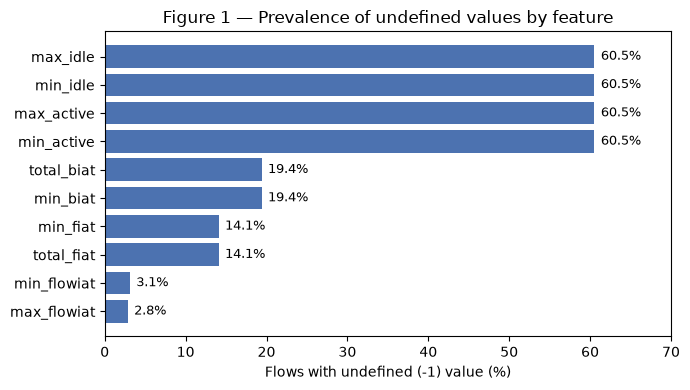

In [5]:
features = df.drop(columns=["class1"])

neg1_summary = pd.DataFrame({
    "count":   (features == -1).sum(),
    "percent": ((features == -1).mean() * 100).round(1),
})
neg1_summary = neg1_summary[neg1_summary["count"] > 0].sort_values("count", ascending=False)
display(neg1_summary)
print("Total -1 cells:", int((features == -1).sum().sum()))

pct = (features == -1).mean() * 100
pct = pct[pct > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(pct.index, pct.values, color="#4C72B0")
ax.set_xlabel("Flows with undefined (-1) value (%)")
ax.set_title("Figure 1 — Prevalence of undefined values by feature")
ax.set_xlim(0, 70)
for i, v in enumerate(pct.values):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("../results/fig1_undefined_values.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Concentrated in the four active/idle features (60.5% of flows each);
inter-arrival totals/minima 14–19%; flow inter-arrival extremes under 4%.
Consistent with short flows having no active/idle transitions.

### Check 2 — How many flows are affected?

Flows with at least one -1: 11,663 (62.2%)


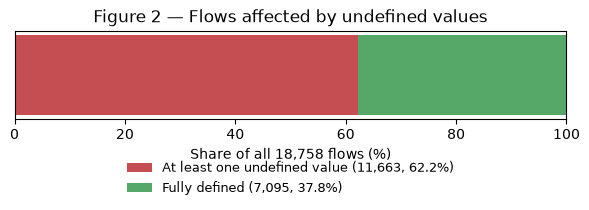

In [6]:
rows_with_neg1 = (features == -1).any(axis=1)
n_aff, n_tot = int(rows_with_neg1.sum()), len(df)
n_clean = n_tot - n_aff
print(f"Flows with at least one -1: {n_aff:,} ({n_aff/n_tot*100:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh([0], [n_aff/n_tot*100], color="#C44E52",
        label=f"At least one undefined value ({n_aff:,}, {n_aff/n_tot*100:.1f}%)")
ax.barh([0], [n_clean/n_tot*100], left=[n_aff/n_tot*100], color="#55A868",
        label=f"Fully defined ({n_clean:,}, {n_clean/n_tot*100:.1f}%)")
ax.set_xlim(0, 100); ax.set_yticks([])
ax.set_xlabel(f"Share of all {n_tot:,} flows (%)")
ax.set_title("Figure 2 — Flows affected by undefined values")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("../results/fig2_flows_affected.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** 62.2% of flows affected, so deletion is not viable: it would discard
almost two-thirds of the data and systematically remove short flows.

### Check 3 — Do undefined values carry class information?

VPN: 5,661 of 9,793 affected = 57.8%
Non-VPN: 6,002 of 8,965 affected = 66.9%


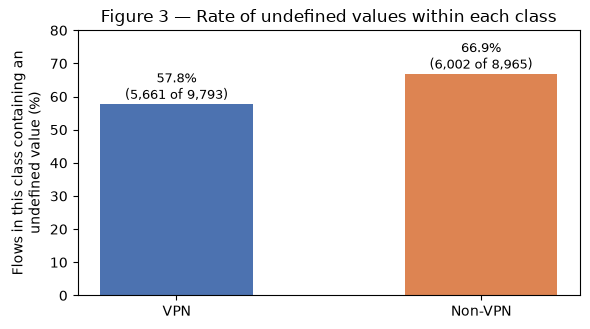

In [7]:
rate = rows_with_neg1.groupby(df["class1"]).mean() * 100
cnt  = rows_with_neg1.groupby(df["class1"]).sum().astype(int)
tot  = df["class1"].value_counts()
for c in ["VPN", "Non-VPN"]:
    print(f"{c}: {cnt[c]:,} of {tot[c]:,} affected = {rate[c]:.1f}%")

order = ["VPN", "Non-VPN"]
fig, ax = plt.subplots(figsize=(6, 3.4))
bars = ax.bar(order, [rate[c] for c in order], width=0.5, color=["#4C72B0", "#DD8452"])
for b, c in zip(bars, order):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5,
            f"{b.get_height():.1f}%\n({cnt[c]:,} of {tot[c]:,})", ha="center", fontsize=9)
ax.set_ylim(0, 80)
ax.set_ylabel("Flows in this class containing an\nundefined value (%)")
ax.set_title("Figure 3 — Rate of undefined values within each class")
plt.tight_layout()
plt.savefig("../results/fig3_class_balance_undefined.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** VPN 57.8% vs Non-VPN 66.9% affected. A modest ~9pp lean, so the
missingness carries mild signal and is not characteristic of one class alone.

### Decision

Deletion ruled out (Check 2). Imputation rejected: values are genuinely undefined,
not missing at random. Re-code `-1` as missing (NaN) and let XGBoost handle it via
its sparsity-aware default-direction splits (Chen & Guestrin, 2016). This preserves
the mild signal found in Check 3.

In [8]:
import numpy as np

df_clean = df.copy()
feature_cols = [c for c in df.columns if c != "class1"]
df_clean[feature_cols] = df_clean[feature_cols].replace(-1, np.nan)

# confirm it worked
print("NaNs now:", int(df_clean[feature_cols].isna().sum().sum()), "(was 0)")
print("-1 remaining:", int((df_clean[feature_cols] == -1).sum().sum()))

NaNs now: 59089 (was 0)
-1 remaining: 0


## 4.2.2 Outlier treatment

Initial inspection showed flows with `duration = 0` and extreme per-second rates
(up to 1e6 packets/s). Three checks establish whether these are genuine traffic or
artefacts of the feature calculation, before deciding how to treat them.

### Check 1 — How extreme are the distributions?

,duration,flowPktsPerSecond,flowBytesPerSecond
count,1.875800e+04,18758.00,1.875800e+04
mean,9.791705e+06,2073.78,4.518895e+05
std,1.438458e+07,19115.71,8.856083e+06
min,0.000000e+00,0.00,0.000000e+00
1%,0.000000e+00,0.00,0.000000e+00
25%,3.346690e+05,2.60,3.862000e+02
50%,1.109263e+07,11.68,2.657060e+03
75%,1.494537e+07,100.67,1.351181e+04
95%,1.499930e+07,5651.98,1.211007e+06
99%,6.023949e+07,48780.49,5.746109e+06


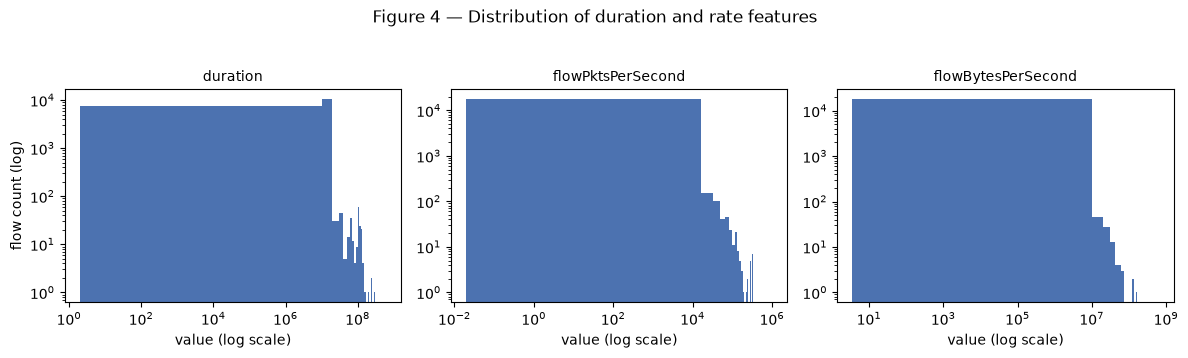

In [9]:
cols = ["duration", "flowPktsPerSecond", "flowBytesPerSecond"]

display(df_clean[cols].describe(percentiles=[.01, .25, .5, .75, .95, .99, .999]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c in zip(axes, cols):
    data = df_clean[c].replace(0, np.nan).dropna()
    ax.hist(data, bins=60, log=True, color="#4C72B0")
    ax.set_xscale("log")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("value (log scale)")
axes[0].set_ylabel("flow count (log)")
fig.suptitle("Figure 4 — Distribution of duration and rate features", y=1.04)
plt.tight_layout()
plt.savefig("../results/fig4_rate_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

 ### Check 2 — The zero-duration flows

duration == 0: 532 flows (2.84%)

Class split of zero-duration flows:
class1
VPN        326
Non-VPN    206
Name: count, dtype: int64

Their rate values:


,duration,flowPktsPerSecond,flowBytesPerSecond
count,532.0,532.0,532.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


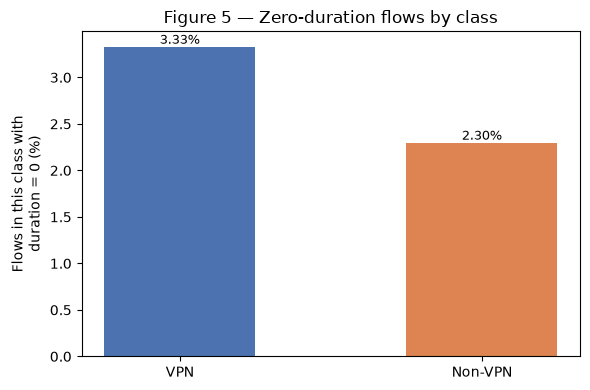

In [10]:
zero_dur = df_clean["duration"] == 0
n_zero = int(zero_dur.sum())
print(f"duration == 0: {n_zero:,} flows ({zero_dur.mean()*100:.2f}%)")

print("\nClass split of zero-duration flows:")
print(df_clean.loc[zero_dur, "class1"].value_counts())

print("\nTheir rate values:")
display(df_clean.loc[zero_dur, cols].describe().round(2))

rate_zero = zero_dur.groupby(df_clean["class1"]).mean() * 100
order = ["VPN", "Non-VPN"]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(order, [rate_zero[c] for c in order], width=0.5, color=["#4C72B0", "#DD8452"])
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"{b.get_height():.2f}%",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Flows in this class with\nduration = 0 (%)")
ax.set_title("Figure 5 — Zero-duration flows by class")
plt.tight_layout()
plt.savefig("../results/fig5_zero_duration.png", dpi=150, bbox_inches="tight")
plt.show()

### Check 3 — Are the extreme rates an artefact of tiny durations?

Flows at/above 99.9th pct of pkts/s (258,679): 19
Overlap with zero-duration flows: 0

Duration of extreme-rate flows:


count    19.00
mean      5.21
std       1.78
min       2.00
25%       3.50
50%       6.00
75%       6.50
max       7.00
Name: duration, dtype: float64

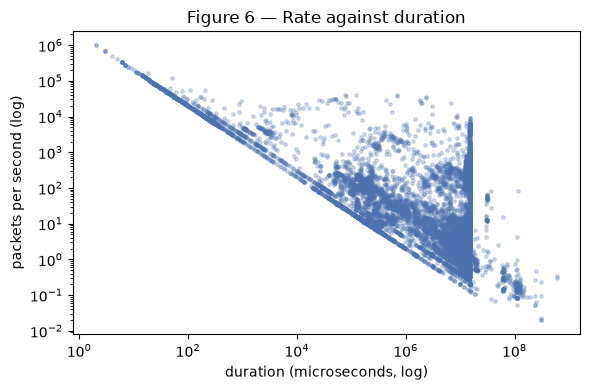

In [11]:
p999 = df_clean["flowPktsPerSecond"].quantile(0.999)
extreme = df_clean["flowPktsPerSecond"] >= p999
print(f"Flows at/above 99.9th pct of pkts/s ({p999:,.0f}): {int(extreme.sum()):,}")
print("Overlap with zero-duration flows:", int((extreme & zero_dur).sum()))

print("\nDuration of extreme-rate flows:")
display(df_clean.loc[extreme, "duration"].describe().round(2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df_clean["duration"].replace(0, np.nan), df_clean["flowPktsPerSecond"],
           s=6, alpha=0.25, color="#4C72B0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("duration (microseconds, log)")
ax.set_ylabel("packets per second (log)")
ax.set_title("Figure 6 — Rate against duration")
plt.tight_layout()
plt.savefig("../results/fig6_rate_vs_duration.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
zero_dur = df_clean["duration"] == 0

# How much of each zero-duration flow is missing (was -1)?
miss_zero = df_clean.loc[zero_dur, feature_cols].isna().mean() * 100
miss_all  = df_clean[feature_cols].isna().mean() * 100

compare = pd.DataFrame({
    "missing % (zero-duration flows)": miss_zero.round(1),
    "missing % (all flows)":           miss_all.round(1),
}).sort_values("missing % (zero-duration flows)", ascending=False)
display(compare)

# How many features are missing per flow, on average?
print("Avg missing features per flow — zero-duration:",
      round(df_clean.loc[zero_dur, feature_cols].isna().sum(axis=1).mean(), 1))
print("Avg missing features per flow — all:",
      round(df_clean[feature_cols].isna().sum(axis=1).mean(), 1))

# Are ALL their features zero or missing?
sub = df_clean.loc[zero_dur, feature_cols]
all_zero_or_nan = ((sub == 0) | sub.isna()).all(axis=1)
print("\nZero-duration flows where EVERY feature is 0 or missing:",
      int(all_zero_or_nan.sum()), f"of {int(zero_dur.sum())}")

# Peek at a few
display(df_clean.loc[zero_dur].head(5))

,missing % (zero-duration flows),missing % (all flows)
total_fiat,100.0,14.1
total_biat,100.0,19.4
min_fiat,100.0,14.1
min_biat,100.0,19.4
max_active,100.0,60.5
min_flowiat,100.0,3.1
max_flowiat,100.0,2.8
min_idle,100.0,60.5
max_idle,100.0,60.5
min_active,100.0,60.5


Avg missing features per flow — zero-duration: 10.0
Avg missing features per flow — all: 3.2

Zero-duration flows where EVERY feature is 0 or missing: 532 of 532


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
421,0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,Non-VPN
871,0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,Non-VPN
993,0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,Non-VPN
994,0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,Non-VPN
995,0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,Non-VPN


### Decision

The heavy-tailed rate distributions are genuine, correctly computed values, and tree
models split on order rather than magnitude, so no transformation or capping is applied.
The 532 zero-duration records contain no measurable traffic (every feature is zero or
undefined) and are removed as extraction artefacts.

In [13]:
before = len(df_clean)
df_clean = df_clean.loc[~zero_dur].reset_index(drop=True)

print(f"Removed {before - len(df_clean):,} zero-duration flows")
print(f"Remaining: {len(df_clean):,} flows")
print("\nClass balance after removal:")
print(df_clean["class1"].value_counts())
print(df_clean["class1"].value_counts(normalize=True).round(3))

Removed 532 zero-duration flows
Remaining: 18,226 flows

Class balance after removal:
class1
VPN        9467
Non-VPN    8759
Name: count, dtype: int64
class1
VPN        0.519
Non-VPN    0.481
Name: proportion, dtype: float64


## 4.2.3 Duplication Record

Initial inspection showed flows with `duration = 0` and extreme per-second rates
(up to 1e6 packets/s). Three checks establish whether these are genuine traffic or
artefacts of the feature calculation, before deciding how to treat them.

In [14]:
# Duplicates across all 23 features (ignoring the label)
dup_feat = df_clean.duplicated(subset=feature_cols, keep=False)
print(f"Rows duplicated on features: {int(dup_feat.sum()):,} ({dup_feat.mean()*100:.2f}%)")

# Full duplicates (features + label)
dup_full = df_clean.duplicated(keep=False)
print(f"Fully identical rows (features + label): {int(dup_full.sum()):,}")

# Conflicting duplicates: same features, different label
if dup_feat.any():
    grp = df_clean[dup_feat].groupby(feature_cols, dropna=False)["class1"].nunique()
    print(f"Duplicate feature-patterns with BOTH labels: {int((grp > 1).sum()):,}")

Rows duplicated on features: 338 (1.85%)
Fully identical rows (features + label): 309
Duplicate feature-patterns with BOTH labels: 22


In [15]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=feature_cols + ["class1"], keep="first").reset_index(drop=True)
print(f"Removed {before - len(df_clean):,} exact duplicates")   # 190
print(f"Remaining: {len(df_clean):,} flows")                     # 18,036
print(df_clean["class1"].value_counts(normalize=True).round(3))  # 0.518 / 0.482

Removed 190 exact duplicates
Remaining: 18,036 flows
class1
VPN        0.518
Non-VPN    0.482
Name: proportion, dtype: float64


### 4.2.4 Label encoding

The target is encoded so that VPN is the positive class (1) and non-VPN the negative
class (0). All precision, recall, and F1 results therefore refer to the VPN class,
which is the class of interest in SQ1.

In [16]:
# VPN = 1 (positive class), Non-VPN = 0
df_clean["label"] = (df_clean["class1"] == "VPN").astype(int)

print(df_clean.groupby("class1")["label"].first())
print("\nPositive class (VPN) count:", int(df_clean["label"].sum()))
print("Proportion positive:", round(df_clean["label"].mean(), 3))

class1
Non-VPN    0
VPN        1
Name: label, dtype: int64

Positive class (VPN) count: 9350
Proportion positive: 0.518


### 4.2.5 Data split

The data is split 80/20 into training and test sets, stratified by class so both
partitions preserve the 51.8/48.2 balance. Hyperparameter tuning will use stratified
5-fold cross-validation *within the training set*, so no separate validation set is
needed and the test set stays untouched until final evaluation.

Note: the feature file carries no session or capture identifier, so a grouped
(leakage-free) split is not possible. This limitation is acknowledged in the report.

In [17]:
X = df_clean[feature_cols]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42,      # fixed seed for reproducibility
)

print(f"Train: {len(X_train):,} flows  ({y_train.mean():.3f} VPN)")
print(f"Test:  {len(X_test):,} flows  ({y_test.mean():.3f} VPN)")
print(f"\nFeatures: {X_train.shape[1]}")
print("Missing values retained for XGBoost's native handling:",
      int(X_train.isna().sum().sum()), "in train,",
      int(X_test.isna().sum().sum()), "in test")

Train: 14,428 flows  (0.518 VPN)
Test:  3,608 flows  (0.518 VPN)

Features: 23
Missing values retained for XGBoost's native handling: 41974 in train, 10477 in test


## 5.1 Exploratory data analysis

All exploratory analysis is performed on the **training set only**, so that the test
set remains unexamined until final evaluation.

This analysis provides model-independent evidence for SQ2: how far each flow-metadata
feature distinguishes VPN from non-VPN traffic on its own.

### 5.1.1 Class separation by feature

Each feature is ranked by how well it separates the two classes on its own, using a
rank-based measure equivalent to the area under the ROC curve (Mann-Whitney U).
A value of 0.5 means no separation; 1.0 would mean perfect separation.

In [18]:
from scipy import stats

train = X_train.copy()
train["label"] = y_train.values

rows = []
for c in feature_cols:
    a = train.loc[train.label == 1, c].dropna()   # VPN
    b = train.loc[train.label == 0, c].dropna()   # non-VPN
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    auc = u / (len(a) * len(b))
    rows.append({
        "feature":     c,
        "sep_AUC":     round(max(auc, 1 - auc), 3),
        "med_VPN":     round(a.median(), 1),
        "med_nonVPN":  round(b.median(), 1),
        "higher_in":   "VPN" if a.median() > b.median() else "non-VPN",
    })

sep = pd.DataFrame(rows).sort_values("sep_AUC", ascending=False).reset_index(drop=True)
display(sep)

,feature,sep_AUC,med_VPN,med_nonVPN,higher_in
0,flowBytesPerSecond,0.621,1600.5,10319.1,non-VPN
1,min_biat,0.618,1579697.5,445117.0,VPN
2,total_biat,0.617,48.0,32.0,VPN
3,flowPktsPerSecond,0.609,9.0,41.6,non-VPN
4,mean_flowiat,0.608,137721.8,26061.7,VPN
5,min_fiat,0.606,1055723.5,234453.0,VPN
6,max_flowiat,0.605,922339.0,172420.0,VPN
7,std_flowiat,0.605,196004.6,13911.3,VPN
8,max_fiat,0.596,207237.0,20004.2,VPN
9,max_biat,0.574,161960.2,20004.5,VPN


#### Figure 7 — Class separation by feature

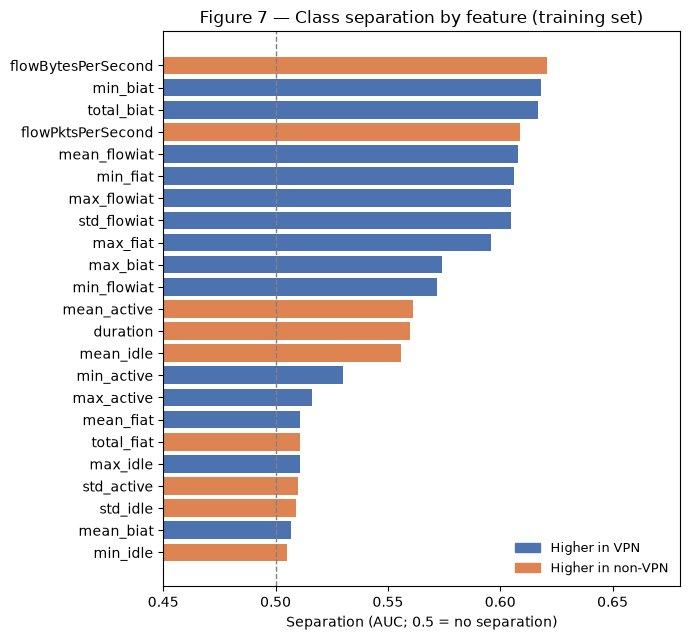

In [19]:
from matplotlib.patches import Patch

s = sep.sort_values("sep_AUC")
colors = ["#4C72B0" if h == "VPN" else "#DD8452" for h in s["higher_in"]]

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(s["feature"], s["sep_AUC"], color=colors)
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.45, 0.68)
ax.set_xlabel("Separation (AUC; 0.5 = no separation)")
ax.set_title("Figure 7 — Class separation by feature (training set)")
ax.legend(handles=[Patch(color="#4C72B0", label="Higher in VPN"),
                   Patch(color="#DD8452", label="Higher in non-VPN")],
          loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig("../results/fig7_feature_separation.png", dpi=150, bbox_inches="tight")
plt.show()

#### Figure 8 — Distributions of the most discriminative features

Plotted on a log scale, since all features are heavily right-skewed.

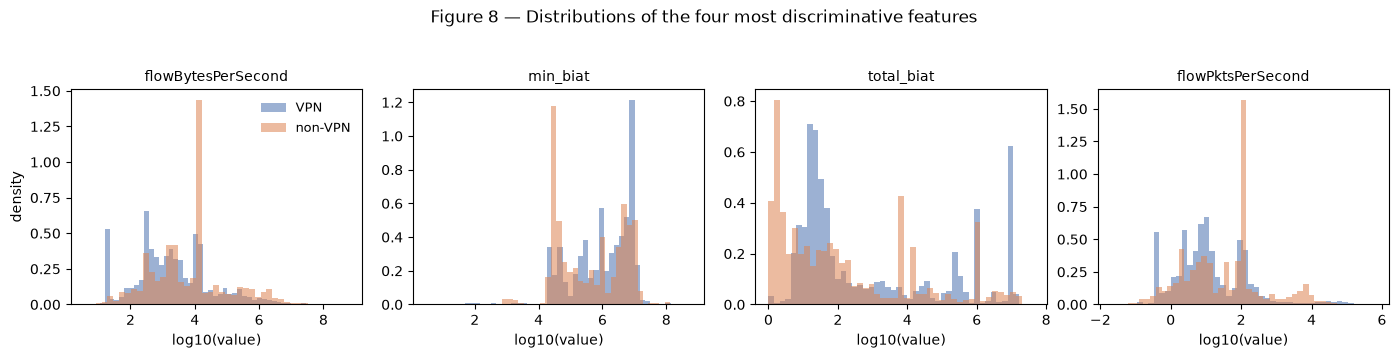

In [20]:
top = sep.head(4)["feature"].tolist()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, c in zip(axes, top):
    for lab, col, name in [(1, "#4C72B0", "VPN"), (0, "#DD8452", "non-VPN")]:
        v = train.loc[train.label == lab, c].dropna()
        v = v[v > 0]                      # log scale needs positive values
        ax.hist(np.log10(v), bins=45, alpha=0.55, color=col, label=name, density=True)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("log10(value)")
axes[0].set_ylabel("density")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Figure 8 — Distributions of the four most discriminative features", y=1.04)
plt.tight_layout()
plt.savefig("../results/fig8_top_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.1.2 Feature correlation

Flow-metadata features describe overlapping aspects of the same traffic behaviour, so
they are expected to be correlated. This matters for SQ2: when two features carry the
same information, a tree model splits between them somewhat arbitrarily and their
importance is divided, which can understate the underlying signal.

Spearman (rank) correlation is used, consistent with the rank-based approach in 5.1.1,
since the features are heavily skewed.

In [21]:
corr = X_train.corr(method="spearman")

# Strongest pairs (upper triangle only, to avoid duplicates)
pairs = (corr.abs()
         .where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack()
         .sort_values(ascending=False))

print(f"Pairs with |rho| >= 0.9: {(pairs >= 0.9).sum()}")
print(f"Pairs with 0.8 <= |rho| < 0.9: {((pairs >= 0.8) & (pairs < 0.9)).sum()}")
print(f"Mean |rho| across all pairs: {pairs.mean():.3f}\n")

print("Ten most correlated pairs:")
display(pairs.head(10).round(3).to_frame("abs_spearman"))

Pairs with |rho| >= 0.9: 10
Pairs with 0.8 <= |rho| < 0.9: 30
Mean |rho| across all pairs: 0.474

Ten most correlated pairs:


,,abs_spearman
max_flowiat,max_idle,1.000
std_active,std_idle,0.996
flowPktsPerSecond,mean_flowiat,0.993
mean_active,mean_idle,0.989
flowBytesPerSecond,mean_flowiat,0.956
min_fiat,max_flowiat,0.952
flowPktsPerSecond,flowBytesPerSecond,0.950
mean_idle,max_idle,0.949
mean_active,max_active,0.922
min_biat,max_flowiat,0.921


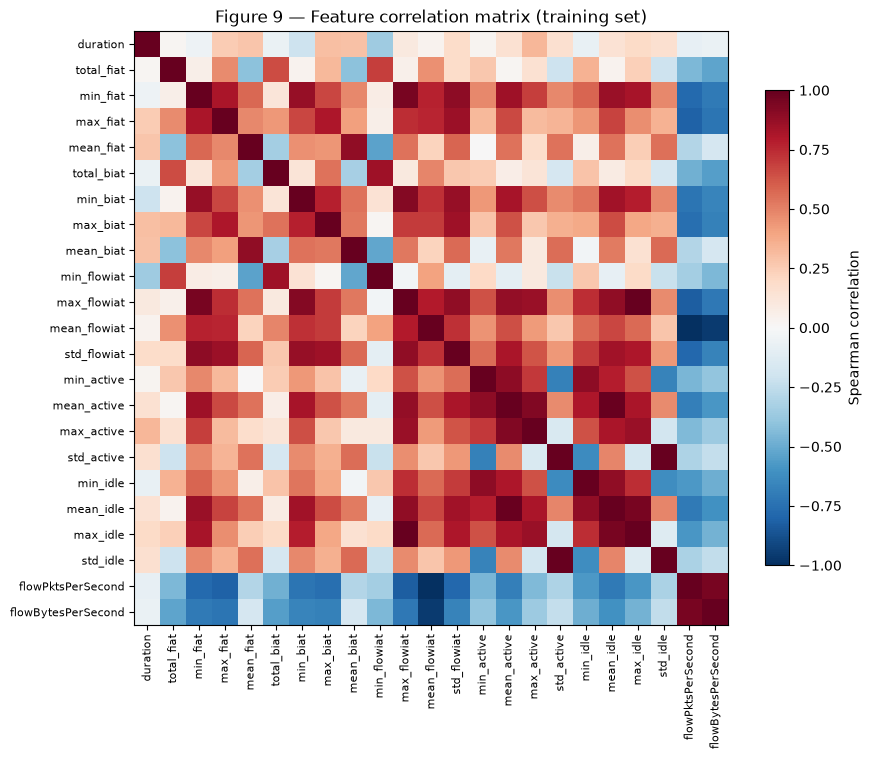

In [22]:
# Order features by group so the block structure is visible
order = ["duration",
         "total_fiat", "min_fiat", "max_fiat", "mean_fiat",
         "total_biat", "min_biat", "max_biat", "mean_biat",
         "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
         "min_active", "mean_active", "max_active", "std_active",
         "min_idle", "mean_idle", "max_idle", "std_idle",
         "flowPktsPerSecond", "flowBytesPerSecond"]
order = [c for c in order if c in feature_cols]
c2 = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(c2.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Figure 9 — Feature correlation matrix (training set)")
plt.tight_layout()
plt.savefig("../results/fig9_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.**

- Substantial redundancy: 10 pairs at |rho| >= 0.9, a further 30 between 0.8 and 0.9,
  mean |rho| = 0.474.
- `max_flowiat` and `max_idle` correlate at **1.000** — the longest gap between packets
  is, by definition, the longest idle period.
- `mean_flowiat` and `flowPktsPerSecond` reach -0.993, since rate is approximately the
  inverse of inter-arrival time.
- The heatmap shows clear block structure: inter-arrival, active, and idle features move
  together, while the two rate features form a separate block correlated negatively with them.
- The 23 features therefore represent a smaller number of underlying quantities measured
  in several ways, which is consistent with the weak univariate separation found in 5.1.1.

**Implication for SQ2.** Features are *not* dropped, since the aim is to measure which
features matter rather than to pre-select them. Instead, importance in 5.3 will be
interpreted at the level of feature groups as well as individual features, and permutation
importance and SHAP will be used as cross-checks, as these handle correlated predictors
better than the built-in gain measure.

## 5.2 Detection results

### 5.2.1 Baseline model

A baseline XGBoost model is trained using the library's default hyperparameters, so
that any later improvement from tuning can be attributed to the tuning itself rather
than to choices made in advance.

The baseline is evaluated by stratified five-fold cross-validation **within the
training set**. The test set is not used at this stage; it is reserved for the final
evaluation in Section 5.2.3.

Missing values are passed to the model unaltered, so that XGBoost applies the
sparsity-aware split finding described in Section 4.2.1.

In [23]:
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold, cross_validate

SEED = 42

baseline = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
    # all other hyperparameters left at library defaults
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results = cross_validate(
    baseline, X_train, y_train,
    cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1,
)

print("Baseline XGBoost — stratified 5-fold CV on the training set\n")
for m in scoring:
    te = cv_results[f"test_{m}"]
    tr = cv_results[f"train_{m}"]
    print(f"{m:<10} val {te.mean():.4f} (+/- {te.std():.4f})   train {tr.mean():.4f}")

Baseline XGBoost — stratified 5-fold CV on the training set

accuracy   val 0.9287 (+/- 0.0029)   train 0.9840
precision  val 0.9254 (+/- 0.0040)   train 0.9845
recall     val 0.9381 (+/- 0.0084)   train 0.9846
f1         val 0.9317 (+/- 0.0031)   train 0.9846
roc_auc    val 0.9809 (+/- 0.0015)   train 0.9989


#### Baseline hyperparameters recorded for reproducibility

In [24]:
import json, sklearn, sys

params = baseline.get_params()
print("XGBoost version :", xgb.__version__)
print("scikit-learn    :", sklearn.__version__)
print("Python          :", sys.version.split()[0])
print("\nDefaults in use:")
for k in ["n_estimators", "max_depth", "learning_rate", "subsample",
          "colsample_bytree", "min_child_weight", "reg_lambda", "gamma"]:
    print(f"  {k:<18} {params.get(k)}")

XGBoost version : 3.2.0
scikit-learn    : 1.9.0
Python          : 3.11.15

Defaults in use:
  n_estimators       None
  max_depth          None
  learning_rate      None
  subsample          None
  colsample_bytree   None
  min_child_weight   None
  reg_lambda         None
  gamma              None


In [25]:
# XGBoost 3.x leaves unset parameters as None until fitting resolves them,
# so we fit once and read the actual values from the booster configuration.
baseline.fit(X_train, y_train)

config = json.loads(baseline.get_booster().save_config())
tp = config["learner"]["gradient_booster"]["tree_train_param"]

print("XGBoost version :", xgb.__version__)
print("scikit-learn    :", sklearn.__version__)
print("Python          :", sys.version.split()[0])
print("\nResolved defaults:")
print(f"  n_estimators       {baseline.get_booster().num_boosted_rounds()}")
for k in ["max_depth", "eta", "subsample", "colsample_bytree",
          "min_child_weight", "lambda", "gamma"]:
    print(f"  {k:<18} {tp.get(k)}")

XGBoost version : 3.2.0
scikit-learn    : 1.9.0
Python          : 3.11.15

Resolved defaults:
  n_estimators       100
  max_depth          6
  eta                0.300000012
  subsample          1
  colsample_bytree   1
  min_child_weight   1
  lambda             1
  gamma              0
